# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [2]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), str(3)
memory usage: 106.6 KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


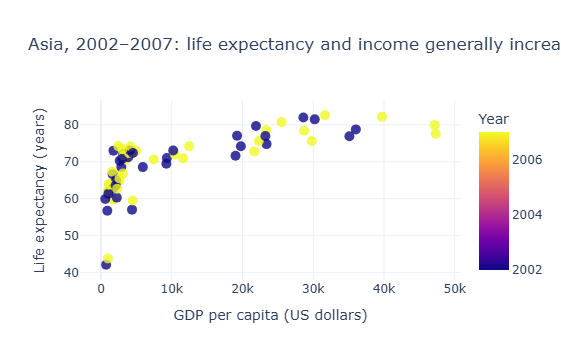

Asia average life expectancy by year:
year
2002    69.23
2007    70.73
Name: lifeExp, dtype: float64

Asia average GDP per capita by year:
year
2002    10174.0
2007    12473.0
Name: gdpPercap, dtype: float64


In [5]:
# Task 1 — Scatter: compare Asia in 2002 and 2007
# One continent only; colour distinguishes the two years.

asia = df.loc[
    (df["continent"] == "Asia") & (df["year"].isin([2002, 2007]))
].copy()

fig1 = px.scatter(
    asia,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={2002: "#2878B5", 2007: "#E07A2D"},
    hover_name="country",
    hover_data={"gdpPercap": ":,.0f", "lifeExp": ":.1f", "year": True},
    title="Asia, 2002–2007: life expectancy and income generally increased",
    labels={
        "gdpPercap": "GDP per capita (US dollars)",
        "lifeExp": "Life expectancy (years)",
        "year": "Year",
    },
)
fig1.update_traces(marker={"size": 10, "opacity": 0.8})
fig1.update_layout(template="plotly_white", legend_title_text="Year")
fig1.show()

# Compare averages to help describe the direction of change.
print("Asia average life expectancy by year:")
print(asia.groupby("year")["lifeExp"].mean().round(2))
print("\nAsia average GDP per capita by year:")
print(asia.groupby("year")["gdpPercap"].mean().round(0))




## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


In [8]:
import plotly.express as px

# Load the Gapminder dataset
gapminder = px.data.gapminder()

# Check that the data loaded correctly
print(gapminder.shape)
print(gapminder.head())
print(gapminder.columns.tolist())

(1704, 8)
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  
['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap', 'iso_alpha', 'iso_num']


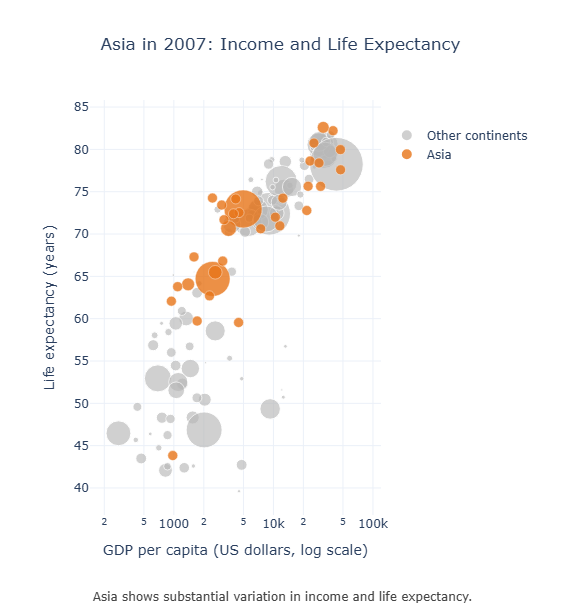

Asia in 2007 - country count: 33
Average life expectancy: 70.7 years
GDP per capita range: $944 to $47307


In [9]:
import plotly.express as px
import plotly.graph_objects as go

# Select all countries for 2007
df_2007 = gapminder[gapminder["year"] == 2007].copy()

# Separate Asia from the other continents
asia_2007 = df_2007[df_2007["continent"] == "Asia"]
other_2007 = df_2007[df_2007["continent"] != "Asia"]

# Create the bubble chart for all other continents
fig2 = px.scatter(
    other_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    hover_name="country",
    size_max=38,
    log_x=True,
    color_discrete_sequence=["#B8B8B8"],
    labels={
        "gdpPercap": "GDP per capita (US dollars, log scale)",
        "lifeExp": "Life expectancy (years)",
        "pop": "Population"
    }
)

# Keep other continents grey
fig2.update_traces(
    marker=dict(opacity=0.65),
    name="Other continents",
    showlegend=True
)

# Add Asia in orange
fig2.add_trace(
    go.Scatter(
        x=asia_2007["gdpPercap"],
        y=asia_2007["lifeExp"],
        mode="markers",
        name="Asia",
        text=asia_2007["country"],
        customdata=asia_2007[["pop"]],
        hovertemplate=(
            "<b>%{text}</b><br>"
            "GDP per capita: $%{x:,.0f}<br>"
            "Life expectancy: %{y:.1f} years<br>"
            "Population: %{customdata[0]:,.0f}"
            "<extra>Asia</extra>"
        ),
        marker=dict(
            color="#E87519",
            opacity=0.8,
            size=asia_2007["pop"],
            sizemode="area",
            sizeref=2.0 * df_2007["pop"].max() / (38**2),
            sizemin=5,
            line=dict(width=0.5, color="white")
        )
    )
)

# Improve chart layout
fig2.update_layout(
    title={
        "text": "Asia in 2007: Income and Life Expectancy",
        "x": 0.5,
        "xanchor": "center"
    },
    width=950,
    height=600,
    margin=dict(l=90, r=180, t=100, b=100),
    legend=dict(
        x=1.02,
        y=0.95
    ),
    template="plotly_white"
)

# Format the logarithmic x-axis
fig2.update_xaxes(
    type="log",
    title="GDP per capita (US dollars, log scale)"
)

fig2.update_yaxes(
    title="Life expectancy (years)"
)

# Add annotation below the plotting area
fig2.add_annotation(
    text="Asia shows substantial variation in income and life expectancy.",
    xref="paper",
    yref="paper",
    x=0,
    y=-0.22,
    xanchor="left",
    showarrow=False,
    font=dict(size=12, color="#444444")
)

# Display the chart
fig2.show()

# Print summary statistics
print(f"Asia in 2007 - country count: {len(asia_2007)}")
print(
    f"Average life expectancy: "
    f"{asia_2007['lifeExp'].mean():.1f} years"
)
print(
    f"GDP per capita range: "
    f"${asia_2007['gdpPercap'].min():.0f} "
    f"to ${asia_2007['gdpPercap'].max():.0f}"
)